In [17]:
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash")


###Pydantic Schema

In [ ]:
from pydantic import Field, BaseModel

class graph_schema(BaseModel) : 

    topic : str = Field(description= "The topic of the graph")
    post : str = Field( description = " this store the post regarding the linkdIn" )

demo_obj = graph_schema(
    topic = " the importance of having AI literacy",
    post = " It is very important to have an AI knowledge "
)




<class '__main__.graph_schema'>
<class 'dict'>


In [26]:
def create_post( state : graph_schema ) -> graph_schema : 

    state = state.model_dump()

    topic = state['topic']

    post = llm.invoke(f'write a linkedIn post about the {topic}').content

    state['post'] = post 
    
    return state

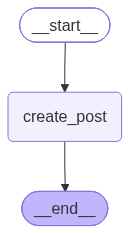

In [27]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)


graph.add_node( 'create_post', create_post)

graph.add_edge( START, 'create_post')
graph.add_edge('create_post', END)


pydantic_graph = graph.compile()

from IPython.display import Image

Image(pydantic_graph.get_graph().draw_mermaid_png())

In [28]:
pydantic_graph.invoke(
   { "topic" : "importance of AI literacy",
     "post" : ""
   }
)

{'topic': 'importance of AI literacy',
 'post': [{'type': 'text',
   'text': 'Here is a draft for a high-engagement LinkedIn post on AI literacy:\n\n***\n\nIn the 1990s, digital literacy became a non-negotiable workplace skill. \n\nIn the 2020s, **AI literacy** is taking that exact same spot. 📱➡️🤖\n\nThere’s a common misconception that "understanding AI" means knowing how to code neural networks or build machine learning models. \n\nIt doesn\'t. \n\n**AI literacy is simply the ability to understand, evaluate, and effectively work alongside AI technologies.**\n\nYou don\'t need a PhD in Data Science to be AI-literate. But you do need to know:\n\n🔹 **How to ask the right questions:** Prompt engineering is becoming the new strategic communication.\n🔹 **How to critically evaluate output:** AI doesn\'t "think"—it predicts. Spotting hallucinations, bias, and inaccuracies is a vital human skill.\n🔹 **Where the boundary lines are:** Understanding data privacy, security, and the ethics of how A